# LAB 2 – Bài 7: Ứng dụng nhận dạng chữ số viết tay – MNIST/digits (Trang 27–31)
Dùng bộ `digits` có sẵn trong sklearn (ảnh 8x8) và cây ID3 để nhận dạng, sau đó nhận dạng ảnh chữ số tự chụp (2 file `test_image_Bai7.jpg` trên Drive, tự tải theo ID). Cần cài `pillow` (`pip install pillow`).


In [1]:
HO_TEN = "Lê Quốc Trung"
MSSV = "6451071082"


def in_ten():
    print(f"{HO_TEN} - {MSSV}")


in_ten()

Lê Quốc Trung - 6451071082


[văn bản liên kết](https://)## Bước 1: Chuẩn bị các thư viện cần thiết

In [2]:
in_ten()
%matplotlib inline
import os
import glob
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split

Lê Quốc Trung - 6451071082


## Bước 2: Tải dữ liệu có sẵn trong thư viện sklearn

In [3]:
in_ten()
# The digits dataset
digits = datasets.load_digits()
print("Số ảnh:", len(digits.images), "| kích thước mỗi ảnh:", digits.images[0].shape, "| số lớp:", len(set(digits.target)))

Lê Quốc Trung - 6451071082
Số ảnh: 1797 | kích thước mỗi ảnh: (8, 8) | số lớp: 10


## Bước 3: Biểu diễn 4 mẫu dữ liệu huấn luyện tương ứng với 4 lớp 0, 1, 2, 3




Lê Quốc Trung - 6451071082


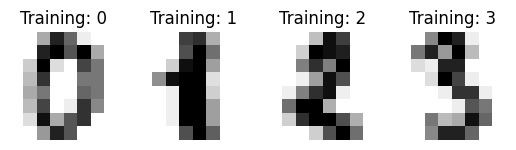

In [4]:
in_ten()
# The data that we are interested in is made of 8x8 images of digits, let's
# have a look at the first 4 images, stored in the `images` attribute of the dataset.
_, axes = plt.subplots(1, 4)
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes, images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title("Training: %i" % label)
plt.show()

## Bước 4: Chuyển mỗi ảnh (ma trận 8x8) thành vector 1x64 để thỏa yêu cầu đầu vào của thuật toán

In [5]:
in_ten()
# To apply a classifier on this data, we need to flatten the image, to
# turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))
print("data:", data.shape)

Lê Quốc Trung - 6451071082
data: (1797, 64)


## Bước 5: Sử dụng thuật toán cây ID3

In [6]:
in_ten()
# Create a classifier: a decision tree classifier
classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)
classifier

Lê Quốc Trung - 6451071082


DecisionTreeClassifier(criterion='entropy', random_state=33)

## Bước 6: Chia dữ liệu thành hai phần: huấn luyện 80%, kiểm thử 20%

In [7]:
in_ten()
# Split data into train and test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.2, shuffle=False)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Lê Quốc Trung - 6451071082
Train: (1437, 64) | Test: (360, 64)


## Bước 7: Tiến hành xây dựng cây ID3

In [8]:
in_ten()
# We learn the digits on the first part of the digits
classifier.fit(X_train, y_train)

Lê Quốc Trung - 6451071082


DecisionTreeClassifier(criterion='entropy', random_state=33)

## Bước 8: Dự đoán nhãn dữ liệu cho tập kiểm thử

In [9]:
in_ten()
# Now predict the value of the digit on the second part:
predicted = classifier.predict(X_test)
print(predicted[:20])

Lê Quốc Trung - 6451071082
[2 3 4 5 6 7 8 9 0 9 5 5 6 5 0 9 8 3 7 4]


## Bước 9: Biểu diễn một vài kết quả dự đoán
> Lưu ý: tài liệu dùng `digits.images[n_samples // 2:]` (đúng với cách chia 50/50 của ví dụ gốc sklearn). Ở đây chia 80/20 nên ảnh kiểm thử là phần **cuối** của dữ liệu (`digits.images[len(X_train):]`), nếu dùng `n_samples // 2` thì ảnh hiển thị sẽ không khớp với nhãn dự đoán.

Lê Quốc Trung - 6451071082


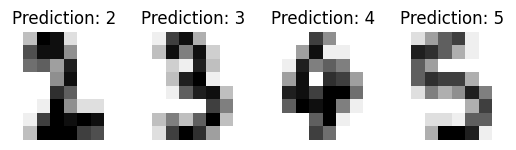

In [10]:
in_ten()
_, axes = plt.subplots(1, 4)
images_and_predictions = list(zip(digits.images[len(X_train):], predicted))
for ax, (image, prediction) in zip(axes, images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title("Prediction: %i" % prediction)
plt.show()

## Bước 10: Thông số đạt được của cây ID3 và ma trận nhầm lẫn

Lê Quốc Trung - 6451071082
Classification report for classifier DecisionTreeClassifier(criterion='entropy', random_state=33):

              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360


Confusion matrix:
[[31  0  0  0  1  0  0  0  1  2]
 [ 0 23  0  2  2  0  0  1  1  7]
 [ 1  2 26  0  0  1  0  3  2 

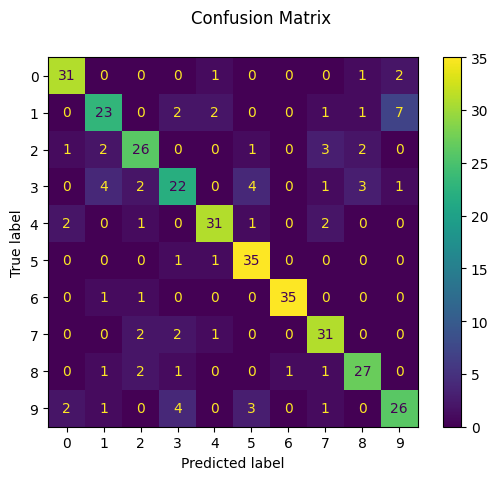

In [11]:
in_ten()
print(f"Classification report for classifier {classifier}:\n\n"
      f"{metrics.classification_report(y_test, predicted)}\n")

# metrics.plot_confusion_matrix đã bị gỡ ở sklearn >= 1.2 -> dùng ConfusionMatrixDisplay
disp = metrics.ConfusionMatrixDisplay.from_predictions(y_test, predicted)
disp.figure_.suptitle("Confusion Matrix")
print(f"Confusion matrix:\n{disp.confusion_matrix}")
plt.show()

## Bước 11: Nhận dạng chữ số viết tay do mình tự chụp
Dùng 2 ảnh `test_image_Bai7.jpg` trên Drive (notebook tự tải về thành `test_image_Bai7_1.jpg` và `test_image_Bai7_2.jpg`), hoặc ảnh tự chụp: cắt hình vuông sát ký tự.
Có thể điều chỉnh `DUONG_DAN_ANH` và `NGUONG` (ở đây là 110) tùy điều kiện ảnh chụp.

Lê Quốc Trung - 6451071082
Đã tải: test_image_Bai7_1.jpg
Đã tải: test_image_Bai7_2.jpg
Các ảnh sẽ dùng: ['test_image_Bai7_1.jpg', 'test_image_Bai7_2.jpg']


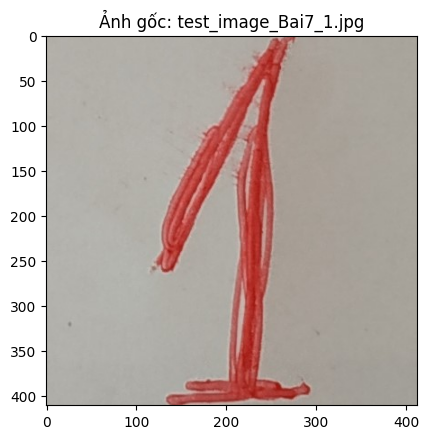

In [12]:
in_ten()
from PIL import Image, ImageOps

import urllib.request

# Trên Drive có 2 file cùng tên test_image_Bai7.jpg -> tải theo ID và lưu thành 2 tên khác nhau
ANH_IDS = {
    "test_image_Bai7_1.jpg": "1BH2qwN62GKZIHcF0kUi0N13YG2eex3wx",
    "test_image_Bai7_2.jpg": "1KU83z5OU2j69YBPI7uMPcLPSUxidd6Ia",
}
for ten, file_id in ANH_IDS.items():
    if not os.path.isfile(ten):
        req = urllib.request.Request(f"https://drive.google.com/uc?export=download&id={file_id}",
                                     headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=120) as r:
            with open(ten, "wb") as f:
                f.write(r.read())
        print("Đã tải:", ten)

cac_anh = sorted(ANH_IDS)
print("Các ảnh sẽ dùng:", cac_anh)

DUONG_DAN_ANH = cac_anh[0]   # đổi sang ảnh khác nếu muốn
NGUONG = 110                 # ngưỡng phân biệt đen/trắng

# Open image
img = Image.open(DUONG_DAN_ANH)
plt.imshow(img)
plt.title("Ảnh gốc: " + DUONG_DAN_ANH)
plt.show()

Lê Quốc Trung - 6451071082


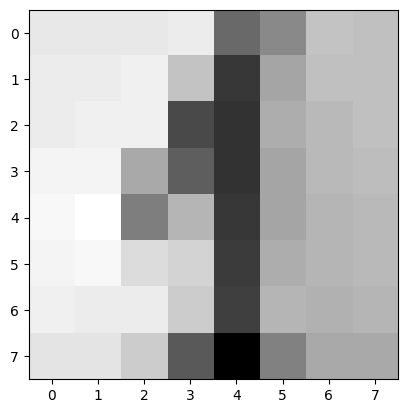

In [13]:
in_ten()
# Open image -> ảnh xám -> 8x8
img = Image.open(DUONG_DAN_ANH).convert("L").resize((8, 8))
# Invert image (nền sáng, nét viết tối -> nền tối, nét viết sáng như dữ liệu digits)
img = ImageOps.invert(img)
# Convert to numpy array
im2arr = np.array(img)
# Show
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation="nearest")
plt.show()

Làm rõ nét lại bức ảnh bằng cách phân biệt rõ những giá trị đen, trắng.

In [14]:
in_ten()
# Change from 2d array (8x8) to 1d array (1x64)  (reshape trả về view nên im2arr cũng thay đổi theo)
img1d = im2arr.reshape([1, 64])
# normalize black & white image array
img1d[img1d > NGUONG - 1] = 155
img1d[img1d < NGUONG] = 0
img1d

Lê Quốc Trung - 6451071082


array([[  0,   0,   0,   0, 155,   0,   0,   0,   0,   0,   0,   0, 155,
          0,   0,   0,   0,   0,   0, 155, 155,   0,   0,   0,   0,   0,
          0, 155, 155,   0,   0,   0,   0,   0,   0,   0, 155,   0,   0,
          0,   0,   0,   0,   0, 155,   0,   0,   0,   0,   0,   0,   0,
        155,   0,   0,   0,   0,   0,   0, 155, 155,   0,   0,   0]],
      dtype=uint8)

Lê Quốc Trung - 6451071082


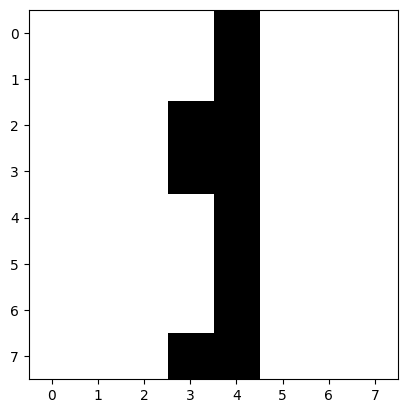

In [15]:
in_ten()
# After normalize
plt.imshow(im2arr, cmap=plt.cm.gray_r, interpolation="nearest")
plt.show()


Tiến hành nhận diện bằng cây ID3 và in ra kết quả.

In [16]:
in_ten()
# Predict label of number
y_pred = classifier.predict(img1d)
print(y_pred)

Lê Quốc Trung - 6451071082
[1]


### Mở rộng: nhận dạng tất cả các ảnh tìm thấy




Lê Quốc Trung - 6451071082
test_image_Bai7_1.jpg -> 1
test_image_Bai7_2.jpg -> 2


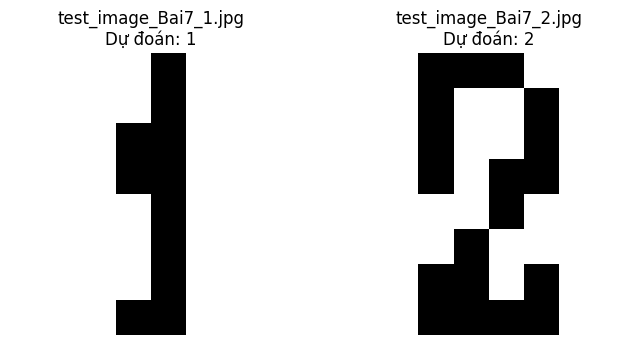

In [17]:
in_ten()


def nhan_dang_anh(duong_dan, nguong=NGUONG):
    anh = ImageOps.invert(Image.open(duong_dan).convert("L").resize((8, 8)))
    mang = np.array(anh).reshape([1, 64])
    mang[mang > nguong - 1] = 155
    mang[mang < nguong] = 0
    return mang, classifier.predict(mang)[0]


fig, axes = plt.subplots(1, len(cac_anh), figsize=(4 * len(cac_anh), 4), squeeze=False)
for ax, p in zip(axes[0], cac_anh):
    mang, nhan = nhan_dang_anh(p)
    ax.imshow(mang.reshape(8, 8), cmap=plt.cm.gray_r, interpolation="nearest")
    ax.set_title(f"{os.path.basename(p)}\nDự đoán: {nhan}")
    ax.set_axis_off()
    print(p, "->", nhan)
plt.show()